## MULTIVARIADA


_“El perfil ambiental de los fabricantes de automóviles a combustion se puede determinar gracias a la relación entre la eficiencia de combustible promedio (MPG) y el volumen de emisiones de gases contaminantes (CO_2). Dividiendo las marcas que cumplen con las normativas ecológicas frente a las que pueden ser n[penalizadas por regulaciones.”_

mejor escrito:

*En vehículos de combustión interna (gasolina y diésel), existe una asociación conjunta inversa entre la eficiencia de combustible promedio corporativa ($MPG$) y la emisión de gases contaminantes ($CO_2$, $CO$, $NO_x$, $THC$), lo que permite jerarquizar a los fabricantes en un espectro de perfil ambiental que distingue a las marcas de alto rendimiento ecológico frente a aquellas de mayor impacto contaminante.*


In [19]:
import pandas as pd
import numpy as np

raw_dataset = pd.read_excel('25-testcar-2026-01-21.xlsx') 
preprocessed_dataset = raw_dataset.copy()

print("Dimensiones iniciales del dataset = [filas, columnas]:", raw_dataset.shape)


pd.options.display.max_columns = None
raw_dataset.head()


columnas_borrar = [ 
    "Model Year",
    "FE_UNIT",
]

preprocessed_dataset.drop(columns=columnas_borrar, inplace=True, errors='ignore')


Dimensiones iniciales del dataset = [filas, columnas]: (4287, 67)


In [20]:

columnas_borrar = [ 
    #conservando el codigo (legibilidad)
    'Drive System Description',
    'Transmission Overdrive Desc',
    'Tested Transmission Type', 
    
    #conservando la descripcion (legibilidad)
    'Shift Indicator Light Use Cd', 
    'Test Procedure Cd', 
    'Test Fuel Type Cd',
    'Aftertreatment Device Cd',
    'Averaging Method Cd'
]

preprocessed_dataset.drop(columns=columnas_borrar, inplace=True, errors='ignore')

print("Dimensiones del dataset luego de la limpieza = ", preprocessed_dataset.shape)

Dimensiones del dataset luego de la limpieza =  (4287, 57)


In [21]:

mpg_combustion = preprocessed_dataset[preprocessed_dataset['Test Fuel Type Description'].str.contains("Gasoline|Diesel")]

mpg_combustion = mpg_combustion[mpg_combustion['RND_ADJ_FE'] <= 100]

cuantil_1 = mpg_combustion['RND_ADJ_FE'].quantile(0.25)
cuantil_3 = mpg_combustion['RND_ADJ_FE'].quantile(0.75)

iqr = cuantil_3 - cuantil_1

limite_inferior = cuantil_1 - 1.5 * iqr
limite_superior = cuantil_3 + 1.5 * iqr

mpg_sin_outliers_combustion = mpg_combustion[(mpg_combustion['RND_ADJ_FE'] >= limite_inferior) & (mpg_combustion['RND_ADJ_FE'] <= limite_superior)]
mpg_sin_outliers_combustion['RND_ADJ_FE'] = mpg_sin_outliers_combustion['RND_ADJ_FE'].round(2)

print(f"El umbral superior estadístico calculado es: {limite_superior:.2f} MPG")
print(mpg_sin_outliers_combustion['RND_ADJ_FE'].describe())

El umbral superior estadístico calculado es: 65.25 MPG
count    3225.000000
mean       32.644465
std        10.974883
min         8.000000
25%        24.000000
50%        31.700000
75%        40.000000
max        65.200000
Name: RND_ADJ_FE, dtype: float64


tipo de combustibles:

'Tier 2 Cert Gasoline',                          -> gasolina

'Cold CO Premium (Tier 2)',                      -> gasolina

'Electricity',               -> electrico

'Cold CO Regular (Tier 2)',  -> gasolina

'E85 (85% Ethanol 15% EPA Unleaded Gasoline)',   -> gasolina

'Federal Cert Diesel 7-15 PPM Sulfur',           -> diesel

'Hydrogen 5',                                    -> hidrogeno

'Cold CO E10 Regular Gasoline (Tier 3)',         -> gasolina

'Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)', -> gasolina

'CARB LEV3 E10 Regular Gasoline',                -> gasolina

'CARB LEV3 E10 Premium Gasoline']                -> gasolina

Agrupación (Groupby): Agrupar el dataset por Vehicle Manufacturer Name y calcular el promedio (media) de sus variables objetivo: RND_ADJ_FE (consumo) y CO2 (g/mi) (emisiones).

In [22]:

mpg_sin_outliers_combustion['Fuel Category'] = mpg_sin_outliers_combustion['Test Fuel Type Description'].apply(
            lambda x: 'Electric' if 'Electric' in str(x) else 
            'Hydrogen' if 'Hydrogen' in str(x)  else
            'Diesel' if 'Diesel' in str(x) else
            'Gasoline')


mpg_sin_outliers_combustion['Fuel Category'].value_counts()


Fuel Category
Gasoline    3075
Diesel       150
Name: count, dtype: int64

In [23]:
fabricantes = (
    mpg_sin_outliers_combustion.groupby(['Vehicle Manufacturer Name', 'Test Vehicle ID', 'Test Veh Configuration #']) #Veh Mfr Code + Test Vehicle ID + Test Veh Configuration
    [['RND_ADJ_FE', 'CO2 (g/mi)','THC (g/mi)', 'CO (g/mi)', 'NOx (g/mi)', 'PM (g/mi)', 'CH4 (g/mi)', 'N2O (g/mi)']].mean().reset_index()
)                  

fabricantes.info()

<class 'pandas.DataFrame'>
RangeIndex: 1087 entries, 0 to 1086
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Vehicle Manufacturer Name  1087 non-null   str    
 1   Test Vehicle ID            1087 non-null   str    
 2   Test Veh Configuration #   1087 non-null   int64  
 3   RND_ADJ_FE                 1087 non-null   float64
 4   CO2 (g/mi)                 1087 non-null   float64
 5   THC (g/mi)                 1066 non-null   float64
 6   CO (g/mi)                  1066 non-null   float64
 7   NOx (g/mi)                 1066 non-null   float64
 8   PM (g/mi)                  193 non-null    float64
 9   CH4 (g/mi)                 1071 non-null   float64
 10  N2O (g/mi)                 961 non-null    float64
dtypes: float64(8), int64(1), str(2)
memory usage: 93.5 KB


In [24]:
fabricantes.head(30)

,Vehicle Manufacturer Name,Test Vehicle ID,Test Veh Configuration #,RND_ADJ_FE,CO2 (g/mi),THC (g/mi),CO (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi)
0,BMW,2U74030,0,44.900000,204.521929,0.005633,0.094941,0.002587,NaN,0.001305,0.000176
1,BMW,2U74030,1,57.400000,151.818995,0.000503,0.030102,0.003190,NaN,0.000472,NaN
2,BMW,2U74030,2,36.300000,239.749793,0.012022,0.184144,0.001882,NaN,0.002917,0.000350
3,BMW,2V15889,0,45.250000,202.240150,0.005125,0.123750,0.001915,NaN,0.001040,0.000130
4,BMW,2V15889,1,46.550000,197.955050,0.005250,0.111800,0.002680,NaN,0.001175,0.000210
5,BMW,2V15889,2,47.700000,193.144200,0.006105,0.101800,0.002615,NaN,0.001575,0.000320
6,BMW,2V17675,0,45.600000,200.108250,0.005660,0.170650,0.002025,NaN,0.001225,0.000150
7,BMW,2V17675,1,46.800000,194.936500,0.006860,0.133800,0.002735,NaN,0.002000,0.000250
8,BMW,2V17675,2,47.300000,193.953800,0.009745,0.182050,0.002585,NaN,0.002595,0.000430
9,BMW,2V87458,0,42.750000,213.297550,0.007220,0.201100,0.001665,NaN,0.001565,0.000130


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

fabricantes_validos = fabricantes.dropna(subset=['RND_ADJ_FE', 'CO2 (g/mi)'])

# Pearson
matriz_corr = fabricantes_validos[['RND_ADJ_FE', 'CO2 (g/mi)']].corr(method='pearson')
print(" MATRIZ DE CORRELACION (Pearson) ")
display(matriz_corr)

 MATRIZ DE CORRELACION (Pearson) 


,RND_ADJ_FE,CO2 (g/mi)
RND_ADJ_FE,1.000000,-0.941313
CO2 (g/mi),-0.941313,1.000000


/tmp/ipykernel_156973/2102801165.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_156973/2102801165.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title=f"Correlación de Pearson: {r:.2f}")


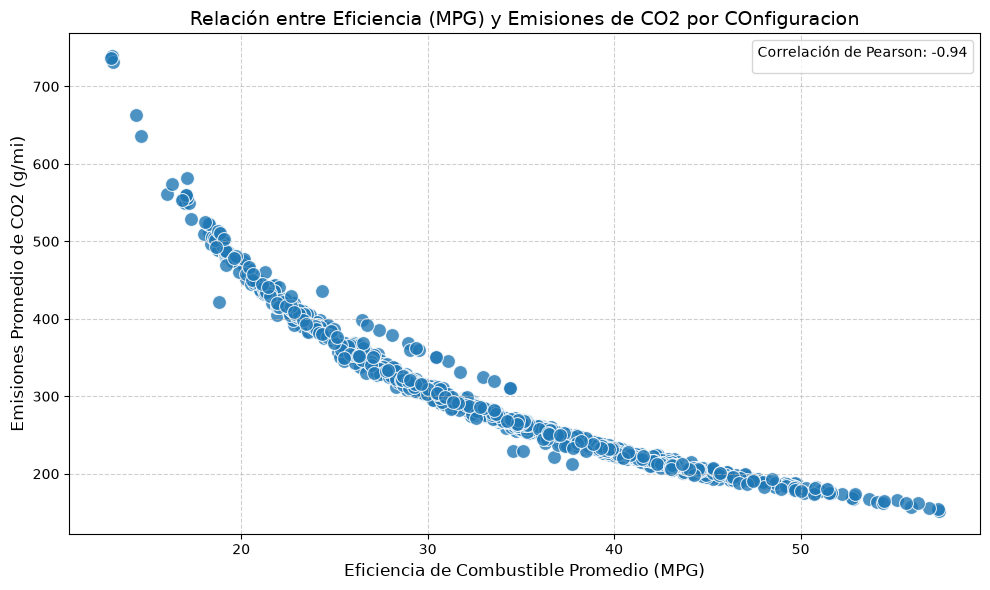

In [26]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=fabricantes_validos, 
    x='RND_ADJ_FE', 
    y='CO2 (g/mi)',
    s=100, 
    alpha=0.8,
    palette='Set1'
)

r, p_value = stats.pearsonr(fabricantes_validos['RND_ADJ_FE'], fabricantes_validos['CO2 (g/mi)'])

plt.title("Relación entre Eficiencia (MPG) y Emisiones de CO2 por COnfiguracion", fontsize=14)
plt.xlabel("Eficiencia de Combustible Promedio (MPG)", fontsize=12)
plt.ylabel("Emisiones Promedio de CO2 (g/mi)", fontsize=12)
plt.legend(title=f"Correlación de Pearson: {r:.2f}")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Construcción de Rankings de Impacto: Se identificarán de forma explícita los Top 5 fabricantes más eficientes y los Top 5 fabricantes más contaminantes, permitiendo un contraste directo de los extremos del mercado.

Validación Visual y Estadística: Se representarán los resultados mediante un diagrama de dispersión (scatter plot) bidimensional cruzando MPG y emisiones de $CO_2$ por marca, respaldado por una matriz de correlación para evaluar la magnitud y dirección de la relación conjunta.

In [27]:

cols_gases_mpg = [
    'RND_ADJ_FE',  
    'CO2 (g/mi)',  
    'CO (g/mi)',   
    'NOx (g/mi)',  
    'THC (g/mi)',  
    'PM (g/mi)',   
    'CH4 (g/mi)',  
    'N2O (g/mi)'   
]

df_gases_limpio = mpg_sin_outliers_combustion[cols_gases_mpg].dropna()

## heatmap de spearman

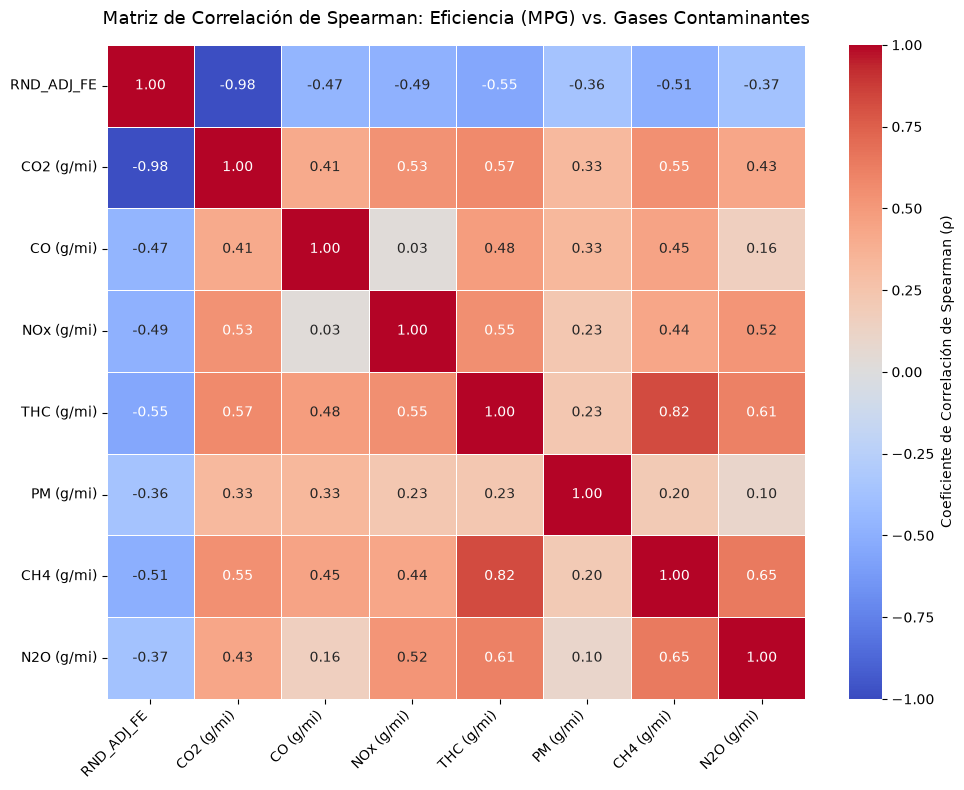

In [28]:
matriz_corr = df_gases_limpio.corr(method='spearman')

plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    annot=True,                 
    fmt='.2f',                  
    cmap='coolwarm',            
    vmin=-1.0,                  
    vmax=1.0,                   
    center=0.0,                 
    linewidths=0.5,             
    cbar_kws={'label': 'Coeficiente de Correlación de Spearman (ρ)'}
)

plt.title("Matriz de Correlación de Spearman: Eficiencia (MPG) vs. Gases Contaminantes", fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


- Relación $MPG$ vs. $CO_2$:
    OBservamos una correlación negativa fuerte (azul intenso, cercana a $-0.90$). Esto confirma que a mayor millas por galon, menor es la cantidad de dióxido de carbono emitida por milla recorrida.

- Relación $MPG$ vs. Contaminantes Nocivos ($NO_x$, $CO$, $THC$, $PM$):
  Muestra la dirección e intensidad real de los gases de combustión incompletos. Si la correlación es negativa débil o moderada, indica que mayor eficiencia reduce estos gases, pero que influyen probablemente otros aspectos tales como la presencia de catalizadores y sistemas de postratamiento (Aftertreatment Device).

- Inter-correlación entre Gases:
  Las celdas entre contaminantes (ej. $NO_x$ con $PM$ o $CO$ con $THC$) revelan qué gases se incrementan o reducen de forma combinada durante el proceso de combustión en el cilindro.

ver relacion de gases nocivos si se usan tratamientos de postratamiento (Aftertreatment Device) y catalizadores, 
estos sistemas reducen significativamente las emisiones de gases nocivos, independientemente de la eficiencia del combustible (MPG).

--- 

# HIPOTESIS MULTIVARIADA
"En vehiculos a combustion en Ruta y Ciudad(Combinado), la cilindrada y la potencia determinan el perfil de contaminacion segun diferentes gases, permitiendo agrupar los vehiculos en un nivel de impacto ambiental segun el postratamiento de escape."

Partiendo de "Engine Displ" y "Horsepower" combinando con gases nocivos como co2, nox y co. 
Luego determinar los que hacen postratamientos a esos gases.

#### Puntos a tener en cuenta
- Para la EPA un mismo modelo esta en varias filas por los diferentes tests, por lo que se debe filtrar por una prueba especifica; luego agrupar por vehiculos y calcular el promedio de los gases, y la potencia para tener una sola fila por modelo.
  
- Herramientas visuales a usar: biplot PCA y heatmap 
  

Decidimos usar los tests _"Comb"_ que represesnta en el estándar de la EPA (55% ciudad + 45% ruta) reflejando el uso real promedio de un conductor típico (Muchas situaciones o trabajos requieren recorrer la ruta para llegar al destino, no siempre se usa solo en la ciudad).
